# Dataset EDA

## Summary
This notebook audits the data actually available for this run. The source-coverage table distinguishes full local releases, convenience probes, shared-image aliases and unavailable sources. Saved results are measurements, not invented examples.

## Context and methods
Images, masks and captions have dataset-specific meanings. Labels are never coerced into a universal ontology. Exact frames and 256-pixel tiles help detect reuse; no exact-match test proves geographic independence. Brightness, outliers and correlations are descriptive, not change truth.

### Key assumptions
- T1/T2 order follows the release.
- One image pair stays in one partition across all its captions/instructions.
- Missing data is unavailable, not a zero-valued observation.
- HLS requires a chosen area/date/product and is not individual-building supervision.

### Set up the project

In [1]:
from pathlib import Path
import os, sys, json, importlib.util, subprocess
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in roots if (p / 'configs/datasets.yaml').exists()), None)
if PROJECT_ROOT is None and IN_COLAB:
    PROJECT_ROOT = Path('/content/TerraWatch')
    if not (PROJECT_ROOT / '.git').exists():
        subprocess.run(['git','clone','--branch','data-pipeline',
            'https://github.com/shoaib2000857/Group-7-DS-and-AI-Lab-Project.git',str(PROJECT_ROOT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(PROJECT_ROOT/'requirements-data.txt')],check=True)
if PROJECT_ROOT is None:
    raise RuntimeError('Clone the project first, then open this notebook in its notebooks folder. See notebooks/README.md.')
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data.catalog import load_catalog
from src.data.preprocess import read_jsonl
AUDIT_DIR = PROJECT_ROOT / 'outputs/data'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'
DATA_ROOT = os.getenv('TERRAWATCH_DATA_ROOT')  # e.g. /content/drive/MyDrive/TerraWatch_Extracted
CONFIG = PROJECT_ROOT / 'configs/datasets.yaml'


In [2]:
# Optional: run only when the datasets are in Google Drive and you are in Colab.
MOUNT_DRIVE = IN_COLAB
if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT = '/content/drive/MyDrive/TerraWatch_Extracted'


## Data
Set `RERUN_AUDIT=True` for a fresh scan. With mounted Drive, the same adapters scan the complete available folders. A local subset is labelled as such; results from different scopes must not be pooled as a common benchmark.

In [3]:
from src.data.audit import run_audit
RERUN_AUDIT = not (AUDIT_DIR / 'audit_summary.json').exists()
MAX_PAIRS = None  # None scans all available records; an integer is a clearly labelled cap
if RERUN_AUDIT:
    run_audit(CONFIG, DATA_ROOT, AUDIT_DIR, max_pairs=MAX_PAIRS, workers=4)
summary = json.loads((AUDIT_DIR / 'audit_summary.json').read_text())
from src.data.plots import availability_table, profile_frame, plot_dataset, plot_correlations, plot_transitions
display(availability_table(summary))

,dataset,status,audited_records,valid_records,scope,missing_joins
0,levir_mci,executed,10077.0,10077.0,all discovered local records,0.0
1,levir_cc,shared_image_alias,NaN,NaN,not counted as independent imagery,NaN
2,levir_cd,not_available_locally,NaN,NaN,not executed,NaN
3,levir_cd_plus,executed,8.0,8.0,convenience Drive probe; not a full-release es...,0.0
4,s2looking,executed,5.0,5.0,convenience Drive probe; not a full-release es...,0.0
5,sysu_cd,executed,8.0,8.0,convenience Drive probe; not a full-release es...,0.0
6,second,not_available_locally,NaN,NaN,not executed,NaN
7,second_cc,executed,6041.0,6041.0,all discovered local records,0.0
8,whu_cdc,not_available_locally,NaN,NaN,not executed,NaN
9,changechat,executed,193042.0,NaN,all local annotation files,NaN


### Dataset roles and label coverage

In [4]:
catalog=load_catalog(CONFIG)
display(pd.DataFrame([{'dataset':d['id'],'target_kind':d['kind'],'supervision':', '.join(d['supervised_classes']),'training_eligible':d['training_eligible'],'source':d['source']} for d in catalog['datasets']]))

,dataset,target_kind,supervision,training_eligible,source
0,levir_mci,mci,"road_change, building_change",True,https://huggingface.co/datasets/lcybuaa/LEVIR-MCI
1,levir_cc,captions,,True,https://github.com/Chen-Yang-Liu/LEVIR-CC-Dataset
2,levir_cd,binary,building_change,True,https://justchenhao.github.io/LEVIR/
3,levir_cd_plus,binary,building_change,True,https://github.com/S2Looking/Dataset
4,s2looking,directional_binary,"building_change, source_label1_mask, source_la...",True,https://github.com/S2Looking/Dataset
5,sysu_cd,binary,general_visible_change,True,https://github.com/liumency/SYSU-CD
6,second,semantic,"water, ground, low_vegetation, trees, building...",True,https://captain-whu.github.io/SCD/
7,second_cc,semantic,"water, ground, low_vegetation, trees, building...",True,https://doi.org/10.5281/zenodo.16937571
8,whu_cdc,binary,building_change,False,https://huggingface.co/datasets/hygge10111/RS-CDC
9,changechat,instructions,,True,https://huggingface.co/datasets/hlwu/changecha...


## Results
Each panel describes only the inspected population listed above. Native dimensions and label proportions are measured before standardisation.

### levir_mci — all discovered local records

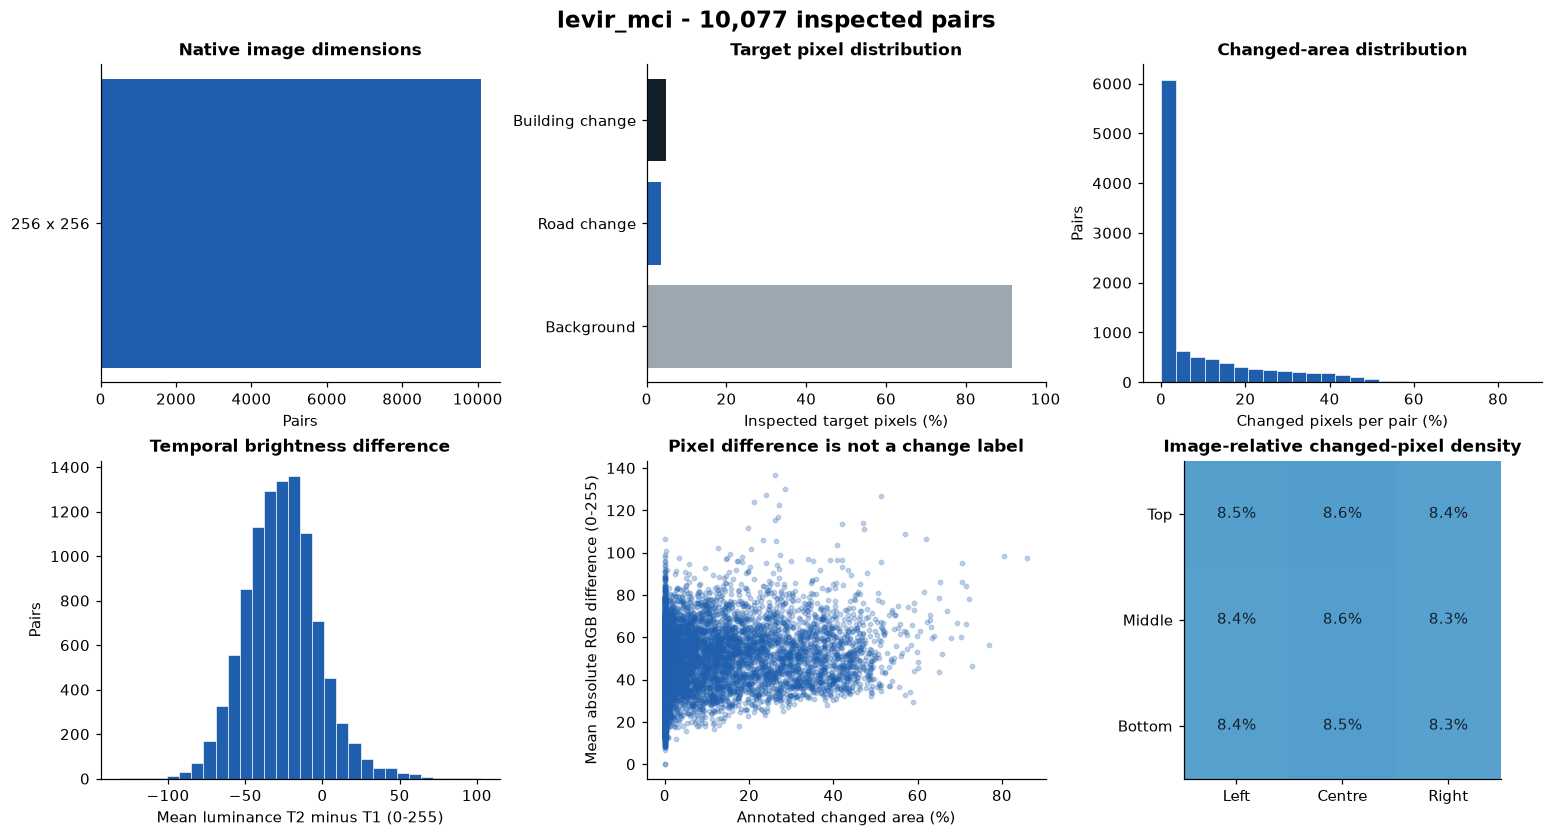

### levir_cd_plus — convenience Drive probe; not a full-release estimate

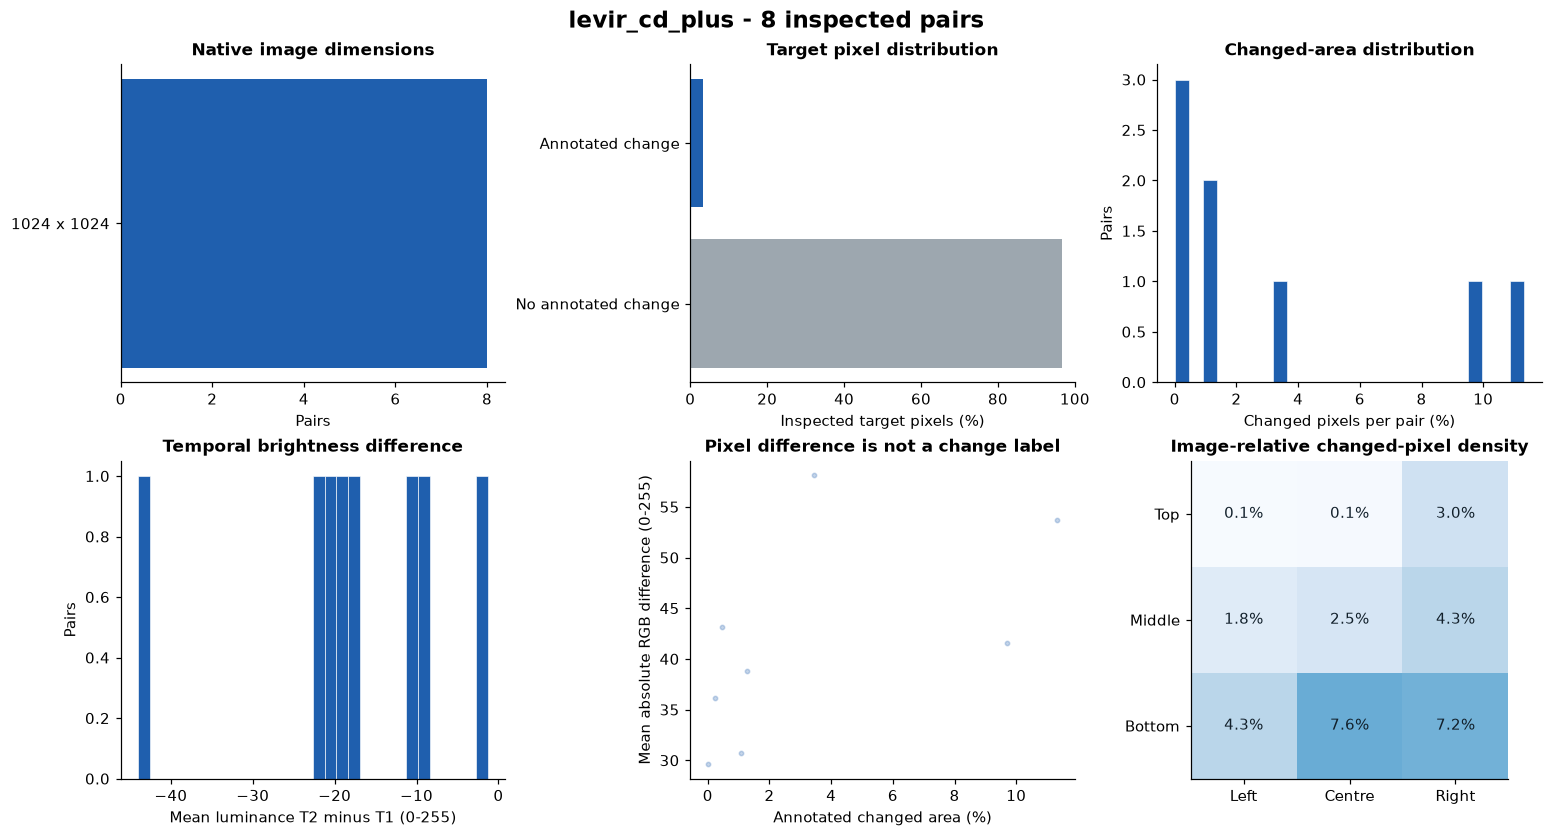

### s2looking — convenience Drive probe; not a full-release estimate

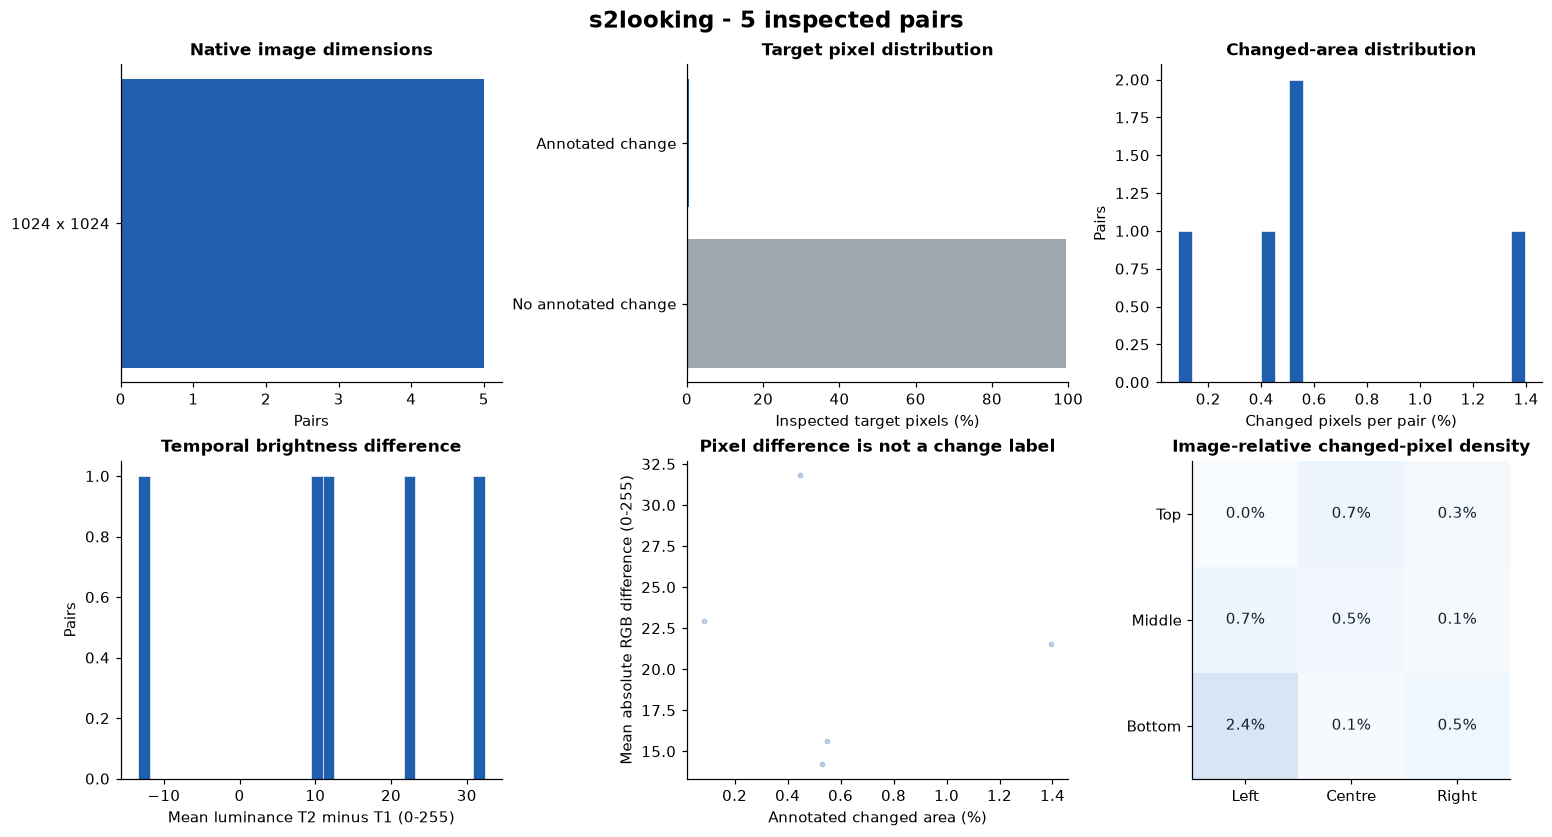

### sysu_cd — convenience Drive probe; not a full-release estimate

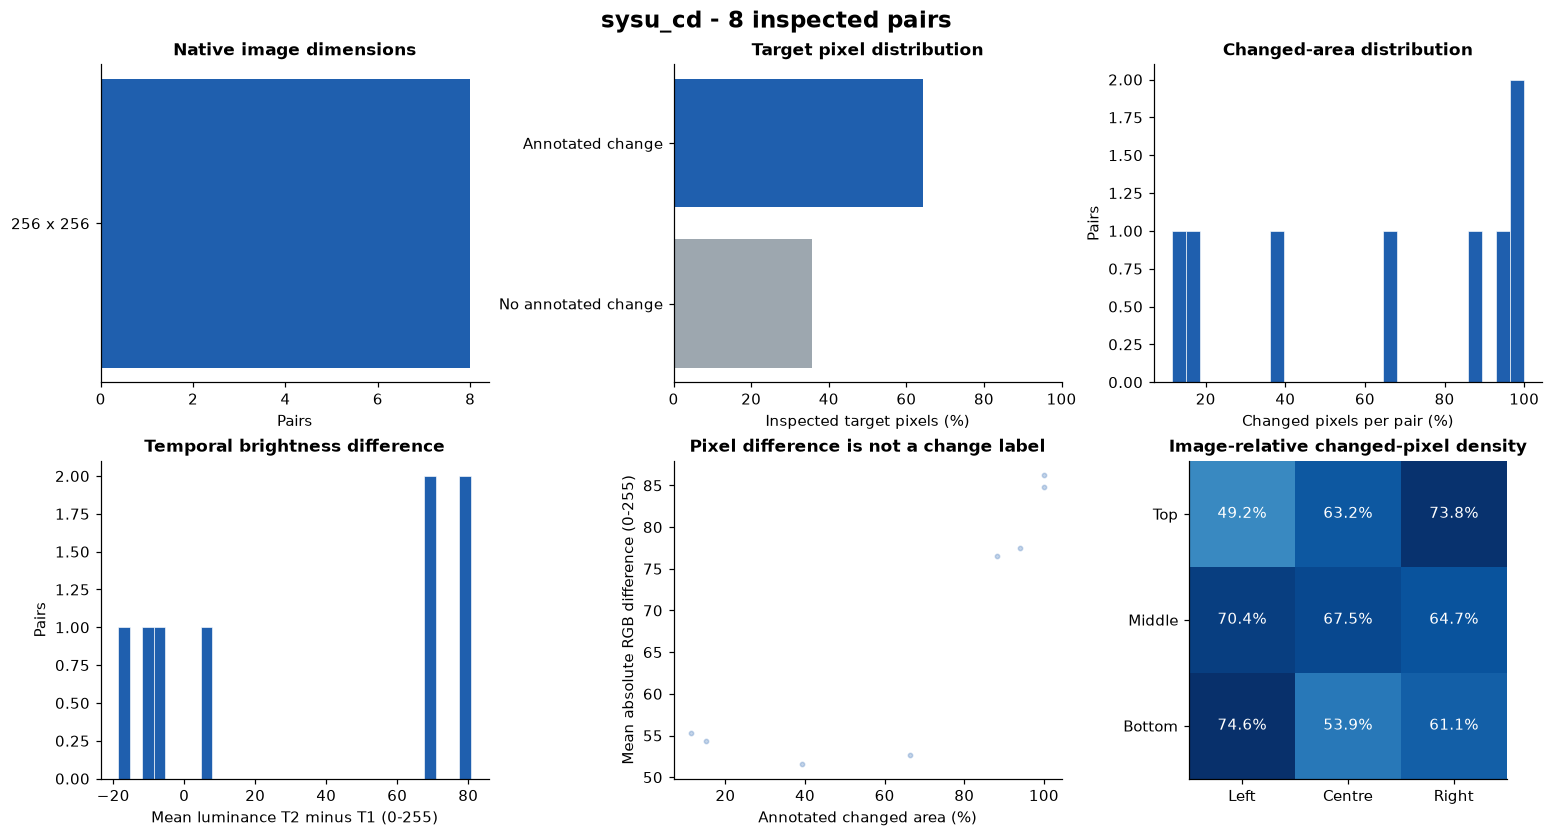

### second_cc — all discovered local records

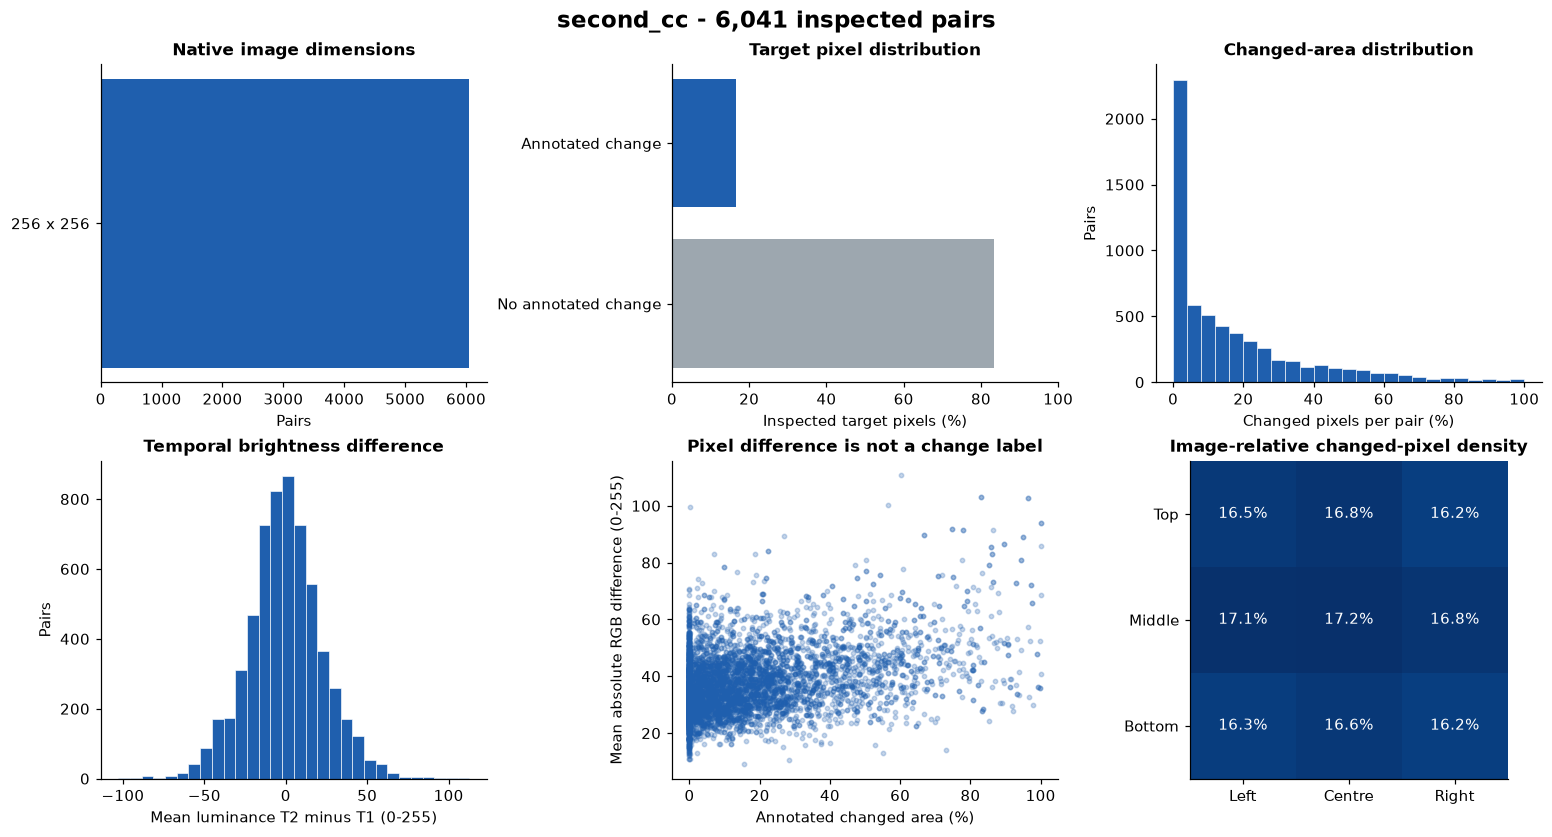

In [5]:
profiles=profile_frame(AUDIT_DIR)
executed=[k for k,v in summary.items() if v['status']=='executed' and v.get('kind')!='instructions']
for dataset in executed:
    if summary[dataset]['valid_records']:
        display(Markdown('### '+dataset+' — '+summary[dataset]['scope']))
        plot_dataset(profiles,dataset); plt.show()
    else:
        display(profiles.loc[profiles.dataset==dataset,['pair_id','error']].head(10))

### Completeness, small changes and conflicts

In [6]:
display(pd.DataFrame([{'dataset':d,'audited':summary[d]['records_audited'],'invalid':summary[d]['invalid_records'],'missing_joins':summary[d]['missing_joins'],'small_changes_under_1pct':summary[d]['small_changes_below_one_percent'],'mask_caption_flags_disagree':summary[d]['mask_caption_conflicts'],'empty_captions':summary[d]['empty_caption_references']} for d in executed]))

,dataset,audited,invalid,missing_joins,small_changes_under_1pct,mask_caption_flags_disagree,empty_captions
0,levir_mci,10077,0,0,408,511,0
1,levir_cd_plus,8,0,0,2,0,0
2,s2looking,5,0,0,4,0,0
3,sysu_cd,8,0,0,0,0,0
4,second_cc,6041,0,0,165,286,0


### Duplicate and leakage evidence
Run the preprocessing notebook for the full exclusion ledger. An exact-frame or tile match can expose cross-release leakage even when filenames differ. Parent-scene independence under arbitrary resampling is outside exact hashing.

In [7]:
from collections import defaultdict
seen=defaultdict(set)
for row in profiles.to_dict('records'):
    if row['valid']:
        for h in row['fingerprints']: seen[h].add(row['pair_id'])
shared=[sorted(ids) for ids in seen.values() if len(ids)>1]
display(pd.DataFrame({'exact_shared_frame_or_tile_groups':[len(shared)]}))
display(pd.DataFrame({'example_pair_ids':shared[:8]}))

,exact_shared_frame_or_tile_groups
0,1974


,example_pair_ids
0,"[levir_cd_plus/train/train_1, levir_mci/test/t..."
1,"[levir_cd_plus/train/train_1, levir_mci/test/t..."
2,"[levir_cd_plus/train/train_1, levir_mci/test/t..."
3,"[levir_cd_plus/train/train_1, levir_mci/test/t..."
4,"[levir_cd_plus/train/train_1, levir_mci/test/t..."
5,"[levir_cd_plus/train/train_1, levir_mci/test/t..."
6,"[levir_cd_plus/train/train_1, levir_mci/test/t..."
7,"[levir_cd_plus/train/train_1, levir_mci/test/t..."


### Outliers and descriptive correlations

,dataset,feature,lower,upper,flagged
0,levir_mci,changed_fraction,-0.192123,0.320206,892
1,levir_mci,brightness_delta,-87.892156,33.871872,195
2,levir_mci,pixel_mae,2.746531,90.123606,71
3,levir_mci,caption_tokens_mean,-4.200000,19.800000,2
4,levir_mci,components_8,-7.500000,12.500000,1305
5,levir_cd_plus,changed_fraction,-0.065369,0.119356,0
6,levir_cd_plus,brightness_delta,-36.893364,6.701759,1
7,levir_cd_plus,pixel_mae,18.306881,62.271250,0
8,levir_cd_plus,components_8,-69.375000,125.625000,1
9,s2looking,changed_fraction,0.002934,0.007031,2


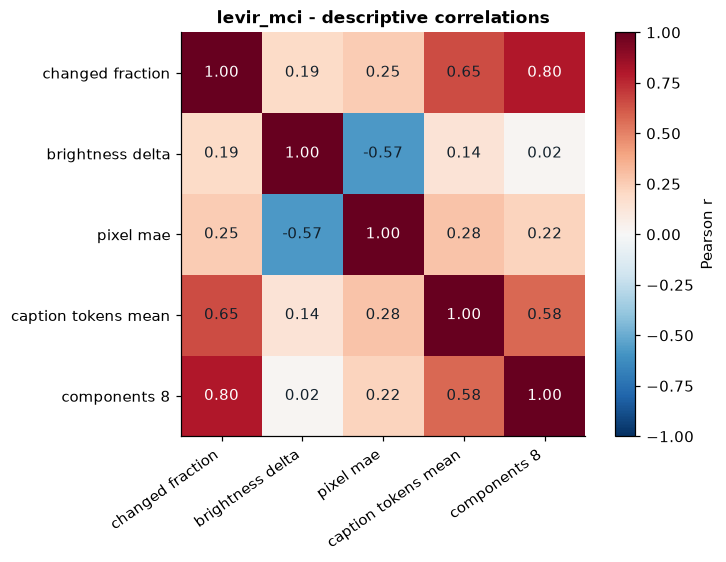

In [8]:
outliers=[]
for d in executed:
    for feature,v in summary[d]['outliers_iqr'].items(): outliers.append(dict(dataset=d,feature=feature,**v))
display(pd.DataFrame(outliers))
plot_correlations(profiles,'levir_mci'); plt.show()

### Semantic transitions

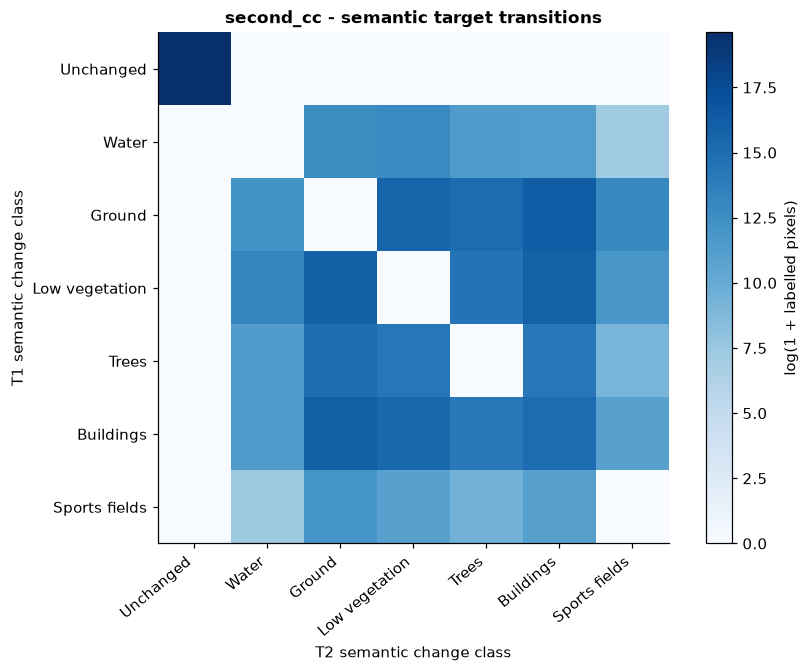

In [9]:
for d in executed:
    if summary[d].get('transition_pixels'):
        plot_transitions(summary,d); plt.show()

### Caption references and instruction variants
ChangeChat rows are derived supervision, not new independent image pairs or human factuality judgements. Train/train-loc files are alternative variants; their raw row counts must not be added as unique examples. Training selects one variant in configuration.

,dataset,reference_captions,largest_repeated_caption_set,lexically_mixed_reference_pairs
0,levir_mci,50385,5039,0
1,second_cc,30159,1703,18


,annotation_rows,unique_image_pairs,exact_duplicate_rows_across_files,missing_image_pairs
0,193042,8744,81120,0


,rows
changechat_105k_test.json,1929
changechat_105k_test_binary.json,1929
changechat_105k_test_count.json,1929
changechat_105k_test_dialog.json,1929
changechat_105k_test_loc.json,1929
changechat_105k_test_open.json,7527
changechat_105k_train.json,87935
changechat_105k_train_loc.json,87935


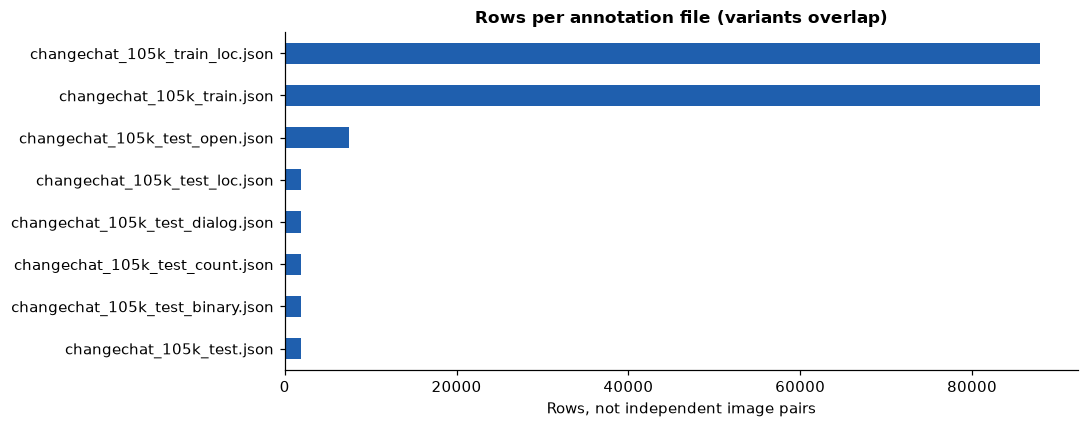

In [10]:
display(pd.DataFrame([{'dataset':d,'reference_captions':summary[d].get('caption_references',0),'largest_repeated_caption_set':summary[d].get('largest_repeated_caption_set',0),'lexically_mixed_reference_pairs':summary[d].get('lexically_mixed_reference_pairs',0)} for d in executed if summary[d].get('caption_references')]))
if 'changechat' in summary and summary['changechat']['status']=='executed':
    s=summary['changechat']
    display(pd.DataFrame([{'annotation_rows':s['records_audited'],'unique_image_pairs':s['unique_parent_pairs'],'exact_duplicate_rows_across_files':s['duplicate_instruction_rows'],'missing_image_pairs':s['missing_parent_rows']}]))
    counts=pd.Series(s['annotation_file_rows'],name='rows')
    display(counts.to_frame())
    ax=counts.plot.barh(figsize=(10,4),color='#1F5FAE',title='Rows per annotation file (variants overlap)'); ax.set_xlabel('Rows, not independent image pairs'); plt.tight_layout(); plt.show()

## Takeaways

In [11]:
for d in executed:
    s=summary[d]
    display(Markdown(f"- **{d}:** {s['records_audited']:,} inspected pairs; {s['invalid_records']} invalid; {s['mask_caption_conflicts']} coarse mask/caption conflicts. Scope: {s['scope']}."))
display(Markdown('Use the measured label coverage and leakage checks when choosing task-specific training data; a larger pooled row count does not establish better generalisation.'))

- **levir_mci:** 10,077 inspected pairs; 0 invalid; 511 coarse mask/caption conflicts. Scope: all discovered local records.

- **levir_cd_plus:** 8 inspected pairs; 0 invalid; 0 coarse mask/caption conflicts. Scope: convenience Drive probe; not a full-release estimate.

- **s2looking:** 5 inspected pairs; 0 invalid; 0 coarse mask/caption conflicts. Scope: convenience Drive probe; not a full-release estimate.

- **sysu_cd:** 8 inspected pairs; 0 invalid; 0 coarse mask/caption conflicts. Scope: convenience Drive probe; not a full-release estimate.

- **second_cc:** 6,041 inspected pairs; 0 invalid; 286 coarse mask/caption conflicts. Scope: all discovered local records.

Use the measured label coverage and leakage checks when choosing task-specific training data; a larger pooled row count does not establish better generalisation.